# Workshop 3 · Cleaning and harmonization

**Course:** ETL (G01) · Universidad Autónoma de Occidente
**Goal:** analyze the 5 *World Happiness* CSV files (2015-2019), detect data quality problems,
propose a **unified schema** and generate the clean dataset used by the model.

**Outputs of this notebook**

| File | Content |
|---|---|
| `data/processed/happiness_unified.csv` | Unified and clean dataset (1 row = country + year) |
| `data/processed/country_region.csv` | Country → region catalog (feeds `dim_country`) |

**Contents**
1. EDA of the original datasets
2. Unified schema proposal
3. Cleaning and harmonization (with the justification of every decision)
4. Outliers
5. Saving and data quality summary

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 200)

RAW_DIR = Path("../data/raw")
PROCESSED_DIR = Path("../data/processed")
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

YEARS = [2015, 2016, 2017, 2018, 2019]

## 1. EDA of the original datasets

### 1.1 Loading and size

In [2]:
raw = {year: pd.read_csv(RAW_DIR / f"{year}.csv") for year in YEARS}

pd.DataFrame({
    "year": YEARS,
    "rows": [raw[y].shape[0] for y in YEARS],
    "columns": [raw[y].shape[1] for y in YEARS],
}).set_index("year")

,rows,columns
year,,
2015,158,12
2016,157,13
2017,155,12
2018,156,9
2019,156,9


### 1.2 Schema differences between years (column names)

A ✔ means the column exists in that year. The names **do not match** between years
(even for the same concept) and every year brings different extra columns.

In [3]:
all_columns = sorted(set().union(*[set(df.columns) for df in raw.values()]))

schema = pd.DataFrame(
    {year: [col in raw[year].columns for col in all_columns] for year in YEARS},
    index=all_columns,
)
schema.map(lambda present: "✔" if present else "-")

,2015,2016,2017,2018,2019
Country,✔,✔,✔,-,-
Country or region,-,-,-,✔,✔
Dystopia Residual,✔,✔,-,-,-
Dystopia.Residual,-,-,✔,-,-
Economy (GDP per Capita),✔,✔,-,-,-
Economy..GDP.per.Capita.,-,-,✔,-,-
Family,✔,✔,✔,-,-
Freedom,✔,✔,✔,-,-
Freedom to make life choices,-,-,-,✔,✔
GDP per capita,-,-,-,✔,✔


**Observations**
- 2015 and 2016 use names such as `Economy (GDP per Capita)`; 2017 uses dots (`Economy..GDP.per.Capita.`);
  2018 and 2019 use another vocabulary (`GDP per capita`, `Social support`, `Perceptions of corruption`...).
- The country column is called `Country` (2015-2017) or `Country or region` (2018-2019).
- `Region` only exists in 2015 and 2016.
- Some columns only exist in some years (`Standard Error`, confidence intervals, `Whisker.*`,
  `Dystopia Residual`, rank) and **are not useful for prediction** (see the target leakage section).

### 1.3 Data types by year

In [4]:
pd.DataFrame({year: raw[year].dtypes.astype(str) for year in YEARS}).fillna("-")

,2015,2016,2017,2018,2019
Country,str,str,str,-,-
Country or region,-,-,-,str,str
Dystopia Residual,float64,float64,-,-,-
Dystopia.Residual,-,-,float64,-,-
Economy (GDP per Capita),float64,float64,-,-,-
Economy..GDP.per.Capita.,-,-,float64,-,-
Family,float64,float64,float64,-,-
Freedom,float64,float64,float64,-,-
Freedom to make life choices,-,-,-,float64,float64
GDP per capita,-,-,-,float64,float64


Types are consistent per concept (text for country/region, integer for rank, decimal for the rest).
There are no numbers stored as text, but they will still be **explicitly standardized** when unifying.

### 1.4 Missing values

In [5]:
missing = pd.DataFrame({year: raw[year].isna().sum() for year in YEARS}).fillna(0).astype(int)
missing[missing.sum(axis=1) > 0]

,2015,2016,2017,2018,2019
Perceptions of corruption,0,0,0,1,0


In [6]:
# Which row is it?
raw[2018][raw[2018].isna().any(axis=1)]

,Overall rank,Country or region,Score,GDP per capita,Social support,Healthy life expectancy,Freedom to make life choices,Generosity,Perceptions of corruption
19,20,United Arab Emirates,6.774,2.096,0.776,0.67,0.284,0.186,NaN


There is only **1 missing value in the whole dataset**: `Perceptions of corruption` of *United Arab Emirates* in 2018.
(`Region` does not count as missing: the column simply does not exist in 2017-2019.)

### 1.5 Duplicated records

In [7]:
def country_col(df):
    return "Country" if "Country" in df.columns else "Country or region"

rows = []
for year in YEARS:
    df = raw[year]
    rows.append({
        "year": year,
        "duplicated_rows": int(df.duplicated().sum()),
        "duplicated_countries": int(df[country_col(df)].duplicated().sum()),
    })
pd.DataFrame(rows).set_index("year")

,duplicated_rows,duplicated_countries
year,,
2015,0,0
2016,0,0
2017,0,0
2018,0,0
2019,0,0


There are no duplicated rows or repeated countries within the same year.

### 1.6 Inconsistent country names between years

If the same country is written differently each year, merging the datasets would treat it as different countries.
These are the countries that **do not appear in all 5 years**:

In [8]:
names = {year: set(raw[year][country_col(raw[year])]) for year in YEARS}
all_countries = sorted(set().union(*names.values()))

presence = pd.DataFrame(
    {year: [c in names[year] for c in all_countries] for year in YEARS},
    index=all_countries,
)
incomplete = presence[~presence.all(axis=1)]
print(f"Distinct countries (not harmonized): {len(all_countries)}")
print(f"Countries that are not in the 5 years: {len(incomplete)}")
incomplete.map(lambda present: "✔" if present else "-")

Distinct countries (not harmonized): 170
Countries that are not in the 5 years: 29


,2015,2016,2017,2018,2019
Angola,✔,✔,✔,✔,-
Belize,-,✔,✔,✔,-
Central African Republic,✔,-,✔,✔,✔
Comoros,✔,✔,-,-,✔
Djibouti,✔,-,-,-,-
Gambia,-,-,-,-,✔
Hong Kong,✔,✔,-,✔,✔
"Hong Kong S.A.R., China",-,-,✔,-,-
Laos,✔,✔,-,✔,✔
Lesotho,✔,-,✔,✔,✔


Two causes are mixed here:
1. **Same country, different name** (fixed): `Hong Kong S.A.R., China` / `Hong Kong`,
   `Taiwan Province of China` / `Taiwan`, `Trinidad & Tobago` / `Trinidad and Tobago`,
   `Northern Cyprus` / `North Cyprus`, `Macedonia` / `North Macedonia`, `Somaliland Region` / `Somaliland region`.
2. **Country that really is not in every year** (kept): for example `Djibouti`, `Oman`,
   `Puerto Rico`, `Gambia` or `Suriname` only appear in some reports. This is normal and not an error.

### 1.7 Ranges and scales per column (original data, columns already aligned)

In [9]:
# Name map: every column variant -> unified name
COLUMN_MAP = {
    # country and region
    "Country": "country", "Country or region": "country", "Region": "region",
    # target
    "Happiness Score": "happiness_score", "Happiness.Score": "happiness_score", "Score": "happiness_score",
    # features
    "Economy (GDP per Capita)": "gdp", "Economy..GDP.per.Capita.": "gdp", "GDP per capita": "gdp",
    "Family": "family", "Social support": "family",
    "Health (Life Expectancy)": "health", "Health..Life.Expectancy.": "health", "Healthy life expectancy": "health",
    "Freedom": "freedom", "Freedom to make life choices": "freedom",
    "Generosity": "generosity",
    "Trust (Government Corruption)": "corruption", "Trust..Government.Corruption.": "corruption",
    "Perceptions of corruption": "corruption",
}

NUMERIC = ["happiness_score", "gdp", "family", "health", "freedom", "generosity", "corruption"]

quick = []
for year in YEARS:
    df = raw[year].rename(columns=COLUMN_MAP)
    part = df[NUMERIC].mean().round(3)
    part.name = year
    quick.append(part)
pd.DataFrame(quick)

,happiness_score,gdp,family,health,freedom,generosity,corruption
2015,5.376,0.846,0.991,0.630,0.429,0.237,0.143
2016,5.382,0.954,0.794,0.558,0.371,0.243,0.138
2017,5.354,0.985,1.189,0.551,0.409,0.247,0.123
2018,5.376,0.891,1.213,0.597,0.455,0.181,0.112
2019,5.407,0.905,1.209,0.725,0.393,0.185,0.111


The yearly means are similar, with one exception: **`family` changes level between years**
(≈0.99 in 2015, ≈0.79 in 2016, ≈1.19 since 2017). This suggests a methodological change in how the report
computes the column (`Family` → `Social support`). It is a known risk of the dataset; since the focus of the
workshop is pipeline integration and not model optimization, the variable is kept and the limitation is documented.

## 2. Unified schema proposal

| Unified column | Type | Source (depending on the year) | Use |
|---|---|---|---|
| `country` | text | `Country` / `Country or region` | Identifier (Kafka event key) |
| `region` | text | `Region` (2015-2016); completed by country for the other years | `dim_country` dimension |
| `year` | integer | File name | Identifier of the observation year |
| `happiness_score` | decimal | `Happiness Score` / `Happiness.Score` / `Score` | **Target** |
| `gdp` | decimal | `Economy (GDP per Capita)` / `GDP per capita` | Feature |
| `family` | decimal | `Family` / `Social support` | Feature |
| `health` | decimal | `Health (Life Expectancy)` / `Healthy life expectancy` | Feature |
| `freedom` | decimal | `Freedom` / `Freedom to make life choices` | Feature |
| `generosity` | decimal | `Generosity` | Feature |
| `corruption` | decimal | `Trust (Government Corruption)` / `Perceptions of corruption` | Feature |

The names of the 6 features and of the target are **exactly those of the Kafka event** defined in the workshop
(`gdp`, `family`, `health`, `freedom`, `generosity`, `corruption`; the target travels as `actual_happiness_score`).

**Dropped columns** (not part of the schema): rank, `Standard Error`, confidence intervals,
`Whisker.high/low` and `Dystopia Residual`. All of them are computed *from the happiness score* or are its
uncertainty, so using them to predict it would be **target leakage**.

## 3. Cleaning and harmonization

### 3.1 Standardize column names and merge the 5 years

In [10]:
UNIFIED_COLUMNS = ["country", "region", "year"] + NUMERIC

frames = []
for year in YEARS:
    df = raw[year].rename(columns=COLUMN_MAP)

    dropped = sorted(set(df.columns) - set(UNIFIED_COLUMNS))
    print(f"{year}: dropped columns -> {dropped}")

    if "region" not in df.columns:      # 2017-2019 have no region
        df["region"] = pd.NA
    df["year"] = year
    frames.append(df[UNIFIED_COLUMNS])

happiness = pd.concat(frames, ignore_index=True)
print()
print("Total rows:", len(happiness))
happiness.head()

2015: dropped columns -> ['Dystopia Residual', 'Happiness Rank', 'Standard Error']
2016: dropped columns -> ['Dystopia Residual', 'Happiness Rank', 'Lower Confidence Interval', 'Upper Confidence Interval']
2017: dropped columns -> ['Dystopia.Residual', 'Happiness.Rank', 'Whisker.high', 'Whisker.low']
2018: dropped columns -> ['Overall rank']
2019: dropped columns -> ['Overall rank']

Total rows: 782


,country,region,year,happiness_score,gdp,family,health,freedom,generosity,corruption
0,Switzerland,Western Europe,2015,7.587,1.39651,1.34951,0.94143,0.66557,0.29678,0.41978
1,Iceland,Western Europe,2015,7.561,1.30232,1.40223,0.94784,0.62877,0.43630,0.14145
2,Denmark,Western Europe,2015,7.527,1.32548,1.36058,0.87464,0.64938,0.34139,0.48357
3,Norway,Western Europe,2015,7.522,1.45900,1.33095,0.88521,0.66973,0.34699,0.36503
4,Canada,North America,2015,7.427,1.32629,1.32261,0.90563,0.63297,0.45811,0.32957


### 3.2 Harmonize country names
**Decision:** the 6 detected variants are unified to the name most used in the other years.
`Macedonia` is unified to `North Macedonia` (current official name, used in 2019).

In [11]:
COUNTRY_FIXES = {
    "Hong Kong S.A.R., China": "Hong Kong",
    "Taiwan Province of China": "Taiwan",
    "Trinidad & Tobago": "Trinidad and Tobago",
    "Northern Cyprus": "North Cyprus",
    "Macedonia": "North Macedonia",
    "Somaliland Region": "Somaliland region",
}

happiness["country"] = happiness["country"].str.strip().replace(COUNTRY_FIXES)

print("Distinct countries before:", len(all_countries))
print("Distinct countries after: ", happiness["country"].nunique())

# Check: a country can no longer be repeated within the same year
assert not happiness.duplicated(["country", "year"]).any()

Distinct countries before: 170
Distinct countries after:  164


### 3.3 Standardize data types
**Decision:** `year` as integer; all metrics as `float64`; `country` and `region` as text without extra spaces.
With `errors="coerce"` any non-numeric value would become `NaN` and would be visible in the next step.

In [12]:
happiness["year"] = happiness["year"].astype("int64")
for col in NUMERIC:
    happiness[col] = pd.to_numeric(happiness[col], errors="coerce").astype("float64")

happiness.dtypes

country                str
region              object
year                 int64
happiness_score    float64
gdp                float64
family             float64
health             float64
freedom            float64
generosity         float64
corruption         float64
dtype: object

### 3.4 Missing values

In [13]:
happiness.isna().sum()

country              0
region             467
year                 0
happiness_score      0
gdp                  0
family               0
health               0
freedom              0
generosity           0
corruption           1
dtype: int64

**Decision for `corruption` (UAE, 2018):** the row is not deleted (a complete country-year with the other
6 variables in good shape would be lost) nor filled with the global mean (UAE has a perceived corruption level very
different from the average). It is filled with **the average of that same country in the other years** (2015-2017 and 2019),
which is the best available estimator because this variable is very stable over time for each country.

**Decision for `region`:** it is not a model feature nor part of the event; it is only used for analysis in
`dim_country`. It is completed with a country→region catalog built from 2015-2016. *Gambia* only appears in 2019
and is not in that catalog; `Sub-Saharan Africa` is assigned manually (same region taxonomy of the report).

In [14]:
# corruption: average of the same country in the other years (mean ignores NaN)
country_mean = happiness.groupby("country")["corruption"].transform("mean")
before = happiness["corruption"].isna().sum()
happiness["corruption"] = happiness["corruption"].fillna(country_mean)
print(f"corruption: {before} missing -> {happiness['corruption'].isna().sum()}")

# region: country -> region catalog
region_lookup = (
    happiness.dropna(subset=["region"])
    .drop_duplicates("country")
    .set_index("country")["region"]
)
happiness["region"] = happiness["country"].map(region_lookup)
happiness["region"] = happiness["region"].fillna(
    happiness["country"].map({"Gambia": "Sub-Saharan Africa"})
)
print(f"region: missing -> {happiness['region'].isna().sum()}")

assert happiness.isna().sum().sum() == 0, "Missing values remain"
happiness[(happiness.country == "United Arab Emirates")]

corruption: 1 missing -> 0
region: missing -> 0


,country,region,year,happiness_score,gdp,family,health,freedom,generosity,corruption
19,United Arab Emirates,Middle East and Northern Africa,2015,6.901,1.427270,1.12575,0.809250,0.641570,0.264280,0.385830
185,United Arab Emirates,Middle East and Northern Africa,2016,6.573,1.573520,0.87114,0.729930,0.562150,0.265910,0.355610
335,United Arab Emirates,Middle East and Northern Africa,2017,6.648,1.626343,1.26641,0.726798,0.608345,0.360942,0.324490
489,United Arab Emirates,Middle East and Northern Africa,2018,6.774,2.096000,0.77600,0.670000,0.284000,0.186000,0.311982
646,United Arab Emirates,Middle East and Northern Africa,2019,6.825,1.503000,1.31000,0.825000,0.598000,0.262000,0.182000


## 4. Outliers

The interquartile range (IQR) rule is used: value < Q1 − 1.5·IQR or > Q3 + 1.5·IQR.

In [15]:
FEATURES = ["gdp", "family", "health", "freedom", "generosity", "corruption"]

rows = []
for col in ["happiness_score"] + FEATURES:
    q1, q3 = happiness[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    n_out = ((happiness[col] < low) | (happiness[col] > high)).sum()
    rows.append({"column": col, "lower_limit": round(low, 3), "upper_limit": round(high, 3),
                 "outliers": int(n_out), "pct": round(100 * n_out / len(happiness), 1)})
pd.DataFrame(rows).set_index("column")

,lower_limit,upper_limit,outliers,pct
column,,,,
happiness_score,1.990,8.709,0,0.0
gdp,-0.338,2.181,0,0.0
family,0.183,2.014,10,1.3
health,-0.112,1.360,0,0.0
freedom,-0.022,0.863,0,0.0
generosity,-0.093,0.502,17,2.2
corruption,-0.099,0.309,68,8.7


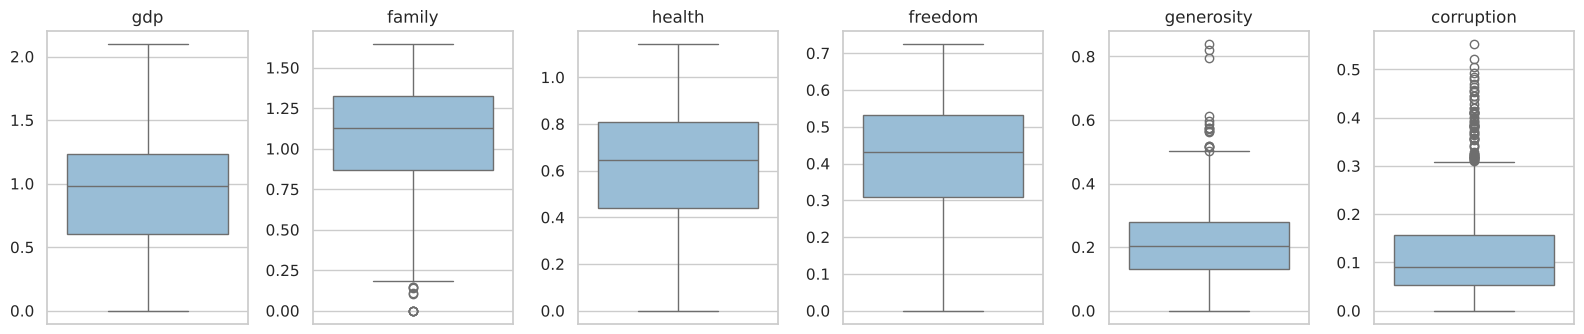

In [16]:
fig, axes = plt.subplots(1, 6, figsize=(16, 3.5))
for ax, col in zip(axes, FEATURES):
    sns.boxplot(y=happiness[col], ax=ax, color="#8fbfe0")
    ax.set_title(col)
    ax.set_ylabel("")
plt.tight_layout()
plt.show()

In [17]:
# Values equal to 0 (they also look like "extremes" in the boxplots)
zeros = happiness[(happiness[FEATURES] == 0).any(axis=1)]
print("Rows with some 0 in the features:", len(zeros))
zeros.head(8)

Rows with some 0 in the features: 30


,country,region,year,happiness_score,gdp,family,health,freedom,generosity,corruption
73,Indonesia,Southeastern Asia,2015,5.399,0.82827,1.08708,0.63793,0.46611,0.51535,0.00000
101,Greece,Western Europe,2015,4.857,1.15406,0.92933,0.88213,0.07699,0.00000,0.01397
111,Iraq,Middle East and Northern Africa,2015,4.677,0.98549,0.81889,0.60237,0.00000,0.17922,0.13788
119,Congo (Kinshasa),Sub-Saharan Africa,2015,4.517,0.00000,1.00120,0.09806,0.22605,0.24834,0.07625
122,Sierra Leone,Sub-Saharan Africa,2015,4.507,0.33024,0.95571,0.00000,0.40840,0.21488,0.08786
147,Central African Republic,Sub-Saharan Africa,2015,3.678,0.07850,0.00000,0.06699,0.48879,0.23835,0.08289
233,Somalia,Sub-Saharan Africa,2016,5.440,0.00000,0.33613,0.11466,0.56778,0.27225,0.31180
244,Bosnia and Herzegovina,Central and Eastern Europe,2016,5.163,0.93383,0.64367,0.70766,0.09511,0.29889,0.00000


**Decision: outliers are kept.**
- They are real and plausible values (for example, countries with very high institutional trust such as Singapore or Rwanda
  raise `corruption`; the distribution of `corruption` and `generosity` is skewed by nature).
- The zeros are not errors: in this report every column is the *contribution* of that variable to the score and the
  country with the lowest value of the sample gets 0 (e.g. *Central African Republic* in `family`).
- The dataset is small (782 rows); removing real cases would make it even poorer, and the percentage of extremes
  is moderate. The final model is evaluated on a test set that training never sees, so any negative
  effect of the outliers would be reflected in the metrics.
- Besides, the consumer validates ranges (0 to 3 per feature), so *impossible* values are rejected in streaming.

## 5. Saving and quality summary

In [18]:
happiness = happiness.sort_values(["year", "country"]).reset_index(drop=True)

# Final check before saving
assert happiness.shape[1] == 10
assert not happiness.duplicated(["country", "year"]).any()
assert happiness.isna().sum().sum() == 0
assert (happiness[FEATURES] >= 0).all().all()

happiness.to_csv(PROCESSED_DIR / "happiness_unified.csv", index=False)

# Country -> region catalog for dim_country
(happiness[["country", "region"]]
    .drop_duplicates("country")
    .sort_values("country")
    .to_csv(PROCESSED_DIR / "country_region.csv", index=False))

print("Unified dataset:", happiness.shape)
print("Countries:", happiness["country"].nunique(), "| Years:", sorted(happiness["year"].unique()))
happiness.groupby("year").size().rename("rows_per_year").to_frame().T

Unified dataset: (782, 10)
Countries: 164 | Years: [np.int64(2015), np.int64(2016), np.int64(2017), np.int64(2018), np.int64(2019)]


year,2015,2016,2017,2018,2019
rows_per_year,158,157,155,156,156


### Summary of data quality observations

| # | Finding | Decision | Justification |
|---|---|---|---|
| 1 | Different column names every year | Rename map to a single schema | Allows merging the years and aligns the name with the Kafka event |
| 2 | Extra non-common columns (rank, SE, CI, whiskers, dystopia) | Dropped | Derived from the target → *target leakage* |
| 3 | `Region` only in 2015-2016 | Country→region catalog; Gambia manual | Useful for `dim_country`; not a feature |
| 4 | 6 countries with a different name across years | Unified with `COUNTRY_FIXES` | Avoids counting the same country twice |
| 5 | 1 missing value (`corruption`, UAE 2018) | Average of the same country in other years | Keeps the row and respects the country level |
| 6 | No duplicates | Verified with `assert` | — |
| 7 | Outliers and zeros (IQR) | Kept | Real values; 0 is the minimum of the scale |
| 8 | `family` changes level between years | Documented as a limitation | Possible methodological change of the report |

**Result:** `data/processed/happiness_unified.csv` — 782 rows × 10 columns, no nulls, no duplicates.